# Two checks on the frozen model: carrying unused budget forward, and calendar drift in the application score

This notebook runs two investigations on the **training months 0–4 only**, with the tuned model frozen on 28 Oct 2026
(LightGBM, the 38 frozen inputs, the settings of `outputs/modelling/models/v1_full/frozen_tuned/manifest.json`).
Neither changes the model, the harness or any agreed setting: both are evidence for team decisions.

**Investigation 1 – carry unused budget forward (a secondary flagging policy).** In the harness the model may flag, in
each week since opening, as many accounts as the rules raised alerts that week, and a flag is permanent. In weeks 1–7
laundering has barely started, so those flags hit almost nothing, while in burst weeks the budget runs out. The idea:
flag only accounts whose score is high (at least a threshold *tau*), and let any unused budget **carry forward** to
later weeks. It stays fair to the rules: at the end of every week the model has used **no more reviews than the rules**
so far. *tau* is chosen on folds 1 and 2 and then applied, untouched, to fold 3 (a rule fixed before looking).

**Investigation 2 – calendar drift in the application score.** Three BAF columns (`velocity_6h`, `velocity_24h`,
`velocity_4w`) fall steadily with the calendar month. The test cohort (accounts opened in months 6 and 7) is ranked
together, so month-7 accounts might get lower (or higher) application scores just because of the month they opened in.
Part (a) measures this **without any label of months 5–7**; part (b) imitates a mixed cohort on the training months
(validate months 3 and 4 ranked together) and checks whether an application score without the three columns costs
anything.

| § | What | Time on v1_full |
|---|---|---|
| 0 | Settings and setup | seconds |
| 1 | The table, application scores, budgets | a few minutes |
| 2 | Out-of-fold scores of the tuned model, 3 seeds × 3 folds | **long** (9 LightGBM fits) |
| 3 | Investigation 1: the policies, the pre-registered choice and verdict | a minute |
| 4 | Investigation 2a: application score by opening month (label-free) | seconds |
| 5 | Investigation 2b: a mixed cohort on the folds | 2 LightGBM fits |
| 6 | Number of looks, report | seconds |

**Rules kept.** Labels only through `amldata.labels()` and the harness's scoring code (`evaluation.score`), and only for
months 0–4. Months 5–7 are read only as public cleaned application columns, for the label-free part (a). Month 5
stays for calibration (4 Nov 2026), months 6–7 for the single final test (5 Nov 2026).

## 0. Settings and setup

In [1]:
import os

DATA = os.environ.get("EDA_DATA", "data/v1_full")   # main dataset
SEEDS = (42, 1, 2)                                  # 42 = the frozen model's seed; 1 and 2 show whether verdicts hold

In [2]:
from __future__ import annotations
import hashlib, json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

# find the repo root (the folder holding src/amldata) so Run All works from notebooks/
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "amldata").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start this notebook from inside the aml-detection-system repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import lightgbm as lgb
from features import candidates
from features.weekly import FEATURES as WEEKLY
from models import drift
from models import feature_lab as fl
from models import lgbm_baseline as base
from evaluation import policy as pol
from evaluation import score as sc

RUN = os.path.basename(os.path.normpath(DATA))
REPORT = Path(os.environ.get("EDA_REPORT", f"outputs/modelling/models/{RUN}/policy_drift"))
REPORT.mkdir(parents=True, exist_ok=True)
MONTHS, WEEKS, W_HI = fl.MONTHS, fl.WEEKS, 26
PARAMS = drift.tuned_params()                       # frozen_tuned settings (random_state 42; overridden per seed)
# seed-to-seed noise of the tuned model on this Mac (PR #43, 5 seeds): largest SD over the 3 folds
NOISE = {"catch_rules": 0.010, "catch_0.1pct": 0.008, "weekly_recall": 0.008}
RUN_HASH = hashlib.sha256((Path(DATA) / "run_manifest.json").read_bytes()).hexdigest()
show = display if "ipykernel" in sys.modules else print
T0 = time.time()
print(f"data {DATA} (run_manifest sha256 {RUN_HASH[:6]}...) -> report {REPORT} | lightgbm {lgb.__version__}")
print("tuned settings:", PARAMS)

data /Users/cheepheng/aml-detection-system/data/v1_full (run_manifest sha256 4ce1c4...) -> report outputs/modelling/models/v1_full/policy_drift | lightgbm 4.7.0
tuned settings: {'class_weight': 'balanced', 'random_state': 42, 'deterministic': True, 'force_row_wise': True, 'verbose': -1, 'learning_rate': 0.032735723260064485, 'n_estimators': 500, 'num_leaves': 15, 'min_child_samples': 2000, 'colsample_bytree': 0.9047505230698577, 'subsample': 0.918855052953664, 'reg_alpha': 3.785717387766898e-05, 'reg_lambda': 0.00045683792971933475, 'subsample_freq': 1}


## 1. The table, the application scores and the rules' budgets

The same rows as the feature lab and notebook 08: one row per account per open week 0–26, accounts opened in months
0–4, weeks after the bank closed an account dropped, label `mule_by_day`, the `roll4` features added at load time.
The application enters as one number, `app_score`, built per fold exactly as the lab builds it (logistic regression,
out of fold for training accounts). Fold 2 (train on months 0–2) also scores **month 4**, for the mixed cohort of
investigation 2; its month 0–3 values are the lab's own.

The **budget** of a validation month is the number of rule alerts on that month's accounts in each week since opening
(`fl.rules_context`, which reads `evaluation.budget`).

In [3]:
t = time.time()
df, _ = base.load_table(DATA, MONTHS, WEEKS, adopted=True)
df = df.sort_values(candidates.KEY, kind="stable").reset_index(drop=True)      # same row order as the lab
df = df[base.KEY + ["open_month", "mule_by_day"] + WEEKLY + candidates.ADOPTED]

lab_app = fl.app_scores(DATA, 42)                                              # the lab's per-fold app scores
APP = {f: lab_app[f]["app_score"] for f in (1, 2, 3)}
extra = drift.fold_app_scores(DATA, (0, 1, 2), (3, 4))                        # same recipe, also scores month 4
gap = (extra.reindex(APP[2].index) - APP[2]).abs().max()
print(f"fold 2: drift.fold_app_scores vs the lab's app score, largest difference {gap:.1e}")
assert gap < 1e-9
month4 = extra.index.difference(APP[2].index)
APP[2] = pd.concat([APP[2], extra.loc[month4]])                                # lab values + month 4

CTX = fl.rules_context(DATA)            # mule account-weeks, the rules' budget per month and week, rules' first alerts
K = CTX["budget"]
TRUTH = {m: sc.cohort_truth(DATA, [m]) for m in (2, 3, 4)}                     # validation months only
print(f"{len(df):,} account-weeks, {int(df.mule_by_day.sum()):,} mule weeks ({time.time() - t:.0f}s)")
show(pd.DataFrame({m: {"accounts": len(TRUTH[m]), "mules by week 26": int(sc.mule_at(TRUTH[m], W_HI).sum()),
                       "rule alerts weeks 0-26": sum(K[m].values())} for m in (2, 3, 4)}).T)

fold 2: drift.fold_app_scores vs the lab's app score, largest difference 8.9e-16


4,449,169 account-weeks, 8,327 mule weeks (20s)


,accounts,mules by week 26,rule alerts weeks 0-26
2,33523,64,170
3,36724,70,165
4,31279,76,166


## 2. Out-of-fold scores of the tuned model

For each seed (42, then 1 and 2) and each fold, the tuned LightGBM is fitted on the training months and scores every
open account-week of the validation month. Only LightGBM's seed changes between seeds; rows, folds and application
scores stay fixed (as the seed-spread check of PR #43). Fits run one at a time.

Check: with seed 42 the weekly recall per fold should be close to the tuned trial of notebook 08 (this Mac's copy of the
data differs from the training machine's, so small differences are expected).

In [4]:
OOF = {}
for seed in SEEDS:
    for f, (train_m, valid_m) in enumerate(base.FOLDS, start=1):
        t = time.time()
        scored = (3, 4) if (seed == 42 and f == 2) else (valid_m,)
        OOF[(seed, f)] = drift.fit_score(df, train_m, scored, APP[f], PARAMS, seed)
        v = OOF[(seed, f)][lambda d: d.open_month == valid_m]
        wr = fl.weekly_recall(fl.weekly_top1(v, v["score"].to_numpy()))
        print(f"seed {seed:2d} fold {f}: train {train_m} -> score {scored}  weekly recall {wr:.4f}  "
              f"({time.time() - t:.0f}s)")

seed 42 fold 1: train (0, 1) -> score (2,)  weekly recall 0.4292  (18s)


seed 42 fold 2: train (0, 1, 2) -> score (3, 4)  weekly recall 0.3966  (25s)


seed 42 fold 3: train (0, 1, 2, 3) -> score (4,)  weekly recall 0.4649  (30s)


seed  1 fold 1: train (0, 1) -> score (2,)  weekly recall 0.4255  (17s)


seed  1 fold 2: train (0, 1, 2) -> score (3,)  weekly recall 0.4062  (38s)


seed  1 fold 3: train (0, 1, 2, 3) -> score (4,)  weekly recall 0.4530  (78s)


seed  2 fold 1: train (0, 1) -> score (2,)  weekly recall 0.4299  (47s)


seed  2 fold 2: train (0, 1, 2) -> score (3,)  weekly recall 0.4036  (64s)


seed  2 fold 3: train (0, 1, 2, 3) -> score (4,)  weekly recall 0.4597  (77s)


In [5]:
trials = Path(f"outputs/modelling/models/{RUN}/lgbm_tuning_step2/trials.csv")
if trials.exists():
    tr = pd.read_csv(trials)
    best = tr.loc[tr["weekly_recall"].idxmax()]
    print("notebook 08, tuned trial, weekly recall per fold:",
          " / ".join(f"{best[f'fold{f}_weekly_recall']:.4f}" for f in (1, 2, 3)))

notebook 08, tuned trial, weekly recall per fold: 0.4302 / 0.4161 / 0.4632


## 3. Investigation 1: carry unused budget forward

**The policies**, all on the same scores of one validation month (weeks 0–26):

* `topk` – the **agreed main policy** (`score.permanent_flags`): each week, the budget's number of highest-scoring open
  accounts not flagged before.
* `carry` – `evaluation.policy.carry_forward_flags`: each week, among accounts not flagged before, flag those with
  score ≥ *tau*, highest first, as long as the model's flags so far never exceed the rules' alerts so far. Two versions:
  no cap, and a cap of 2× that week's budget in any single week (a week with no rule alerts then gets no flags).
* `model_anytime` – the harness's secondary upper bound (`score.anytime_flags`): the same total number of flags spent
  whenever the model likes, with one threshold over the whole horizon. It is **not** fair week by week (it can use
  next month's reviews today), so it is only a yardstick.
* `rules` – the rules' own first alerts.

**Pre-registered procedure (fixed before running).** *tau* is a quantile of all the month's account-week scores, from
the grid {0.99, 0.995, 0.998, 0.999, 0.9995}. Choose the quantile with the most mules caught over **folds 1 + 2
combined** (tie: the higher quantile), separately for cap and no cap; apply that quantile, untouched, to **fold 3**
(fold 3 is scored only for the chosen quantiles). Verdict: **holds up** only if on fold 3 it catches at least as many
mules as `topk` AND its median days from laundering start to first flag is no later; **better** only if it also
catches more on folds 1 and 2. Repeated with seeds 1 and 2.

Measures (`score.measures`, the harness's own): **caught** = mules by the end of week 26 flagged by then; **median days
from start** to first flag (negative = before the laundering started; a model flag is dated at the end of its week);
**caught by start week** = first flag no later than the end of the laundering start week; **flags** used; **precision**
= share of flags that are mules; **catch_mean** = per week, the share of that week's mules already flagged, averaged.

*Caveat on tau.* A quantile of the whole month's 27 weeks of scores is only known at the end of the horizon. In use,
*tau* would have to be fixed in score units beforehand (e.g. from month 5). No label is involved, but it is a mild look
ahead at the score distribution, so the result is optimistic in that respect.

In [6]:
COLS = ["flagged", "caught", "mules", "precision", "median_days_from_start", "caught_by_start_week", "catch_mean",
        "flagged_before_start", "caught_fake", "caught_witting", "caught_unwitting"]


def run_policies(seed, f, quantiles):
    valid_m = base.FOLDS[f - 1][1]
    live = OOF[(seed, f)][lambda d: d.open_month == valid_m]
    k, truth = K[valid_m], TRUTH[valid_m]
    flags = {"topk": sc.permanent_flags(live, k), "model_anytime": sc.anytime_flags(live, sum(k.values())),
             "rules": sc.rules_flags(truth, W_HI)}
    meta = {name: {"quantile": np.nan, "tau": np.nan, "cap": ""} for name in flags}
    for q in quantiles:
        tau = pol.quantile_tau(live, q)
        for cap in (None, pol.CAP):
            name = f"carry_{'cap' if cap else 'nocap'}_q{q}"
            flags[name] = pol.carry_forward_flags(live, k, tau, cap)
            assert pol.within_budget(flags[name], k), name          # never ahead of the rules' reviews
            meta[name] = {"quantile": q, "tau": tau, "cap": "cap" if cap else "nocap"}
    summ, weekly = sc.measures(truth, flags, W_HI)
    mules = truth["account_id"][sc.mule_at(truth, W_HI)]
    summ["caught_by_start_week"] = [pol.caught_by_start_week(truth, flags[p], mules) for p in summ["policy"]]
    summ = summ.assign(seed=seed, fold=f, valid_month=valid_m, **{c: summ["policy"].map(lambda p: meta[p][c])
                                                                  for c in ("quantile", "tau", "cap")})
    weekly["budget"] = weekly["week"].map(k).fillna(0).astype(int)
    return summ, weekly.assign(seed=seed, fold=f)


rows, weeklies, choice = [], [], []
for seed in SEEDS:
    for f in (1, 2):                                       # selection folds: every quantile
        s, w = run_policies(seed, f, pol.QUANTILES)
        rows.append(s); weeklies.append(w)
    sel = pd.concat([r for r in rows if r["seed"].iat[0] == seed])
    chosen = {}
    for cap in ("nocap", "cap"):
        c = sel[sel["cap"] == cap]
        chosen[cap] = pol.choose_quantile(c)
    s, w = run_policies(seed, 3, sorted(set(chosen.values())))   # fold 3: only the chosen quantiles
    s = s[(s["cap"] == "") | s.apply(lambda r: r["cap"] != "" and chosen[r["cap"]] == r["quantile"], axis=1)]
    rows.append(s); weeklies.append(w)
    allr = pd.concat([r for r in rows if r["seed"].iat[0] == seed])
    tk = allr[allr["policy"] == "topk"].sort_values("fold")
    for cap, q in chosen.items():
        p = allr[(allr["cap"] == cap) & (allr["quantile"] == q)].sort_values("fold")
        choice.append({"seed": seed, "cap": cap, "quantile": q,
                       "caught_folds12_choice": int(p.loc[p.fold.isin([1, 2]), "caught"].sum()),
                       "caught_folds12_topk": int(tk.loc[tk.fold.isin([1, 2]), "caught"].sum()),
                       **{f"caught_f{f}": int(p.loc[p.fold == f, "caught"].iat[0]) for f in (1, 2, 3)},
                       **{f"topk_caught_f{f}": int(tk.loc[tk.fold == f, "caught"].iat[0]) for f in (1, 2, 3)},
                       "median_days_f3": p.loc[p.fold == 3, "median_days_from_start"].iat[0],
                       "topk_median_days_f3": tk.loc[tk.fold == 3, "median_days_from_start"].iat[0],
                       "verdict": pol.policy_verdict(p, tk)})
POL = pd.concat(rows, ignore_index=True)
WEEKLY_FLAGS = pd.concat(weeklies, ignore_index=True)
CHOICE = pd.DataFrame(choice)
print(f"policies done ({time.time() - T0:.0f}s since start)")
show(CHOICE)

policies done (435s since start)


,seed,cap,quantile,caught_folds12_choice,caught_folds12_topk,caught_f1,caught_f2,caught_f3,topk_caught_f1,topk_caught_f2,topk_caught_f3,median_days_f3,topk_median_days_f3,verdict
0,42,nocap,0.9995,119,116,58,61,68,57,59,63,6.0,7.0,better
1,42,cap,0.9995,119,116,58,61,68,57,59,63,6.0,7.0,better
2,1,nocap,0.9995,118,115,57,61,66,57,58,64,6.0,8.0,holds up
3,1,cap,0.9995,117,115,57,60,65,57,58,64,6.0,8.0,holds up
4,2,nocap,0.9995,120,118,58,62,67,59,59,64,6.0,7.0,holds up
5,2,cap,0.9995,120,118,58,62,65,59,59,64,6.0,7.0,holds up


### The selection folds: every quantile, seed 42

Mules caught over folds 1 + 2 for each quantile, against the main policy. The pre-registered choice is the row with
the most catches (per cap setting).

In [7]:
sel42 = POL[(POL.seed == 42) & POL.fold.isin([1, 2])]
grid = sel42[sel42.cap != ""].pivot_table(index=["cap", "quantile"], columns="fold",
                                          values=["caught", "median_days_from_start", "flagged"]).round(1)
show(grid)
show(sel42[sel42.policy == "topk"].set_index("fold")[["flagged", "caught", "median_days_from_start"]])

caught       flagged        median_days_from_start     
fold                1     2       1      2                      1    2
cap   quantile                                                        
cap   0.9900     57.0  59.0   170.0  165.0                    6.0  8.0
      0.9950     57.0  59.0   170.0  165.0                    6.0  8.0
      0.9980     57.0  59.0   170.0  165.0                    6.0  8.0
      0.9990     57.0  59.0   170.0  165.0                    5.0  7.0
      0.9995     58.0  61.0   134.0  146.0                    6.0  7.0
nocap 0.9900     57.0  59.0   170.0  165.0                    6.0  8.0
      0.9950     57.0  59.0   170.0  165.0                    6.0  8.0
      0.9980     57.0  59.0   170.0  165.0                    6.0  8.0
      0.9990     57.0  59.0   170.0  165.0                    5.0  7.0
      0.9995     58.0  61.0   140.0  149.0                    6.0  7.0

,flagged,caught,median_days_from_start
fold,,,
1,170,57,6.0
2,165,59,8.0


### Fold 3 (held back) and the folds side by side, seed 42

`topk` is the agreed main policy; `carry_*` use the quantile chosen on folds 1 + 2.

In [8]:
s42 = POL[POL.seed == 42].copy()
CH42 = CHOICE[CHOICE.seed == 42].set_index("cap")["quantile"]
s42 = s42[(s42.cap == "") | s42.apply(lambda r: r["cap"] != "" and CH42[r["cap"]] == r["quantile"], axis=1)]
s42["policy"] = s42["policy"].str.replace(r"_q[0-9.]+$", "", regex=True)
order = ["topk", "carry_nocap", "carry_cap", "model_anytime", "rules"]
s42["policy"] = pd.Categorical(s42["policy"], order, ordered=True)
T42 = s42.sort_values(["fold", "policy"]).set_index(["fold", "policy"])[["quantile"] + COLS]
T42["quantile"] = T42["quantile"].map(lambda q: "" if pd.isna(q) else f"{q:g}")
show(T42.round(3))

quantile  flagged  caught  mules  precision  \
fold policy                                                      
1    topk                        170      57     64      0.335   
     carry_nocap     0.9995      140      58     64      0.414   
     carry_cap       0.9995      134      58     64      0.433   
     model_anytime               170      58     64      0.341   
     rules                       165      19     64      0.115   
2    topk                        165      59     70      0.358   
     carry_nocap     0.9995      149      61     70      0.409   
     carry_cap       0.9995      146      61     70      0.418   
     model_anytime               165      61     70      0.370   
     rules                       150      18     70      0.120   
3    topk                        166      63     76      0.380   
     carry_nocap     0.9995      103      68     76      0.660   
     carry_cap       0.9995      103      68     76      0.660   
     model_anytime               166      69     76      0.416   
     rules                       152      21     76      0.138   

                    median_days_from_start  caught_by_start_week  catch_mean  \
fold policy                                                                    
1    topk                              6.0                    33       0.477   
     carry_nocap                       6.0                    30       0.479   
     carry_cap                         6.0                    30       0.479   
     model_anytime                     6.0                    32       0.480   
     rules                             6.0                     2       0.146   
2    topk                              8.0                    24       0.453   
     carry_nocap                       7.0                    30       0.467   
     carry_cap                         7.0                    29       0.466   
     model_anytime                     7.0                    30       0.467   
     rules                            10.0                     2       0.132   
3    topk                              7.0                    30       0.436   
     carry_nocap                       6.0                    36       0.468   
     carry_cap                         6.0                    36       0.468   
     model_anytime                     6.0                    39       0.488   
     rules                             5.0                     5       0.143   

                    flagged_before_start caught_fake caught_witting  \
fold policy                                                           
1    topk                              0       50/56            2/3   
     carry_nocap                       0       51/56            2/3   
     carry_cap                         0       51/56            2/3   
     model_anytime                     0       51/56            2/3   
     rules                             0       17/56            0/3   
2    topk                              0       49/57            5/7   
     carry_nocap                       0       51/57            4/7   
     carry_cap                         0       51/57            4/7   
     model_anytime                     0       51/57            4/7   
     rules                             0       14/57            2/7   
3    topk                              2       55/65            2/4   
     carry_nocap                       0       60/65            2/4   
     carry_cap                         0       60/65            2/4   
     model_anytime                     1       61/65            2/4   
     rules                             0       18/65            0/4   

                   caught_unwitting  
fold policy                          
1    topk                       5/5  
     carry_nocap                5/5  
     carry_cap                  5/5  
     model_anytime              5/5  
     rules                      2/5  
2    topk                       5/6  
     carry_nocap       

### Is the difference larger than seed noise?

The yardstick is how much the **main policy's** catches move when only LightGBM's seed changes (3 seeds here), and,
for `catch_mean`, the seed SD measured in PR #43 (0.010 for the lab's `catch_rules`, the same measure).

In [9]:
tk_all = POL[POL.policy == "topk"]
SEED_SD = tk_all.groupby("fold")[["caught", "catch_mean", "median_days_from_start"]].std(ddof=1)
show(SEED_SD.round(3).rename(columns=lambda c: f"topk seed SD: {c}"))
gain = []
for _, r in CHOICE.iterrows():
    for f in (1, 2, 3):
        p = POL[(POL.seed == r.seed) & (POL.cap == r.cap) & (POL["quantile"] == r["quantile"]) & (POL.fold == f)].iloc[0]
        t_ = POL[(POL.seed == r.seed) & (POL.policy == "topk") & (POL.fold == f)].iloc[0]
        gain.append({"seed": r.seed, "cap": r.cap, "fold": f, "d_caught": p.caught - t_.caught,
                     "d_median_days": p.median_days_from_start - t_.median_days_from_start,
                     "d_caught_by_start_week": p.caught_by_start_week - t_.caught_by_start_week,
                     "d_catch_mean": p.catch_mean - t_.catch_mean, "d_precision": p.precision - t_.precision})
GAIN = pd.DataFrame(gain)
show(GAIN.round(3))

,topk seed SD: caught,topk seed SD: catch_mean,topk seed SD: median_days_from_start
fold,,,
1,1.155,0.011,0.577
2,0.577,0.005,0.577
3,0.577,0.007,0.577


,seed,cap,fold,d_caught,d_median_days,d_caught_by_start_week,d_catch_mean,d_precision
0,42,nocap,1,1,0.0,-3,0.002,0.079
1,42,nocap,2,2,-1.0,6,0.015,0.052
2,42,nocap,3,5,-1.0,6,0.032,0.281
3,42,cap,1,1,0.0,-3,0.002,0.098
4,42,cap,2,2,-1.0,5,0.014,0.060
5,42,cap,3,5,-1.0,6,0.032,0.281
6,1,nocap,1,0,-1.0,4,0.001,0.078
7,1,nocap,2,3,-1.0,6,0.026,0.058
8,1,nocap,3,2,-2.0,8,0.031,0.237
9,1,cap,1,0,-1.0,4,0.001,0.090


### How the budget is spent (seed 42, fold 3)

Cumulative flags against the rules' cumulative alerts (the ceiling for both fair policies), and the share of each
week's mules already flagged.

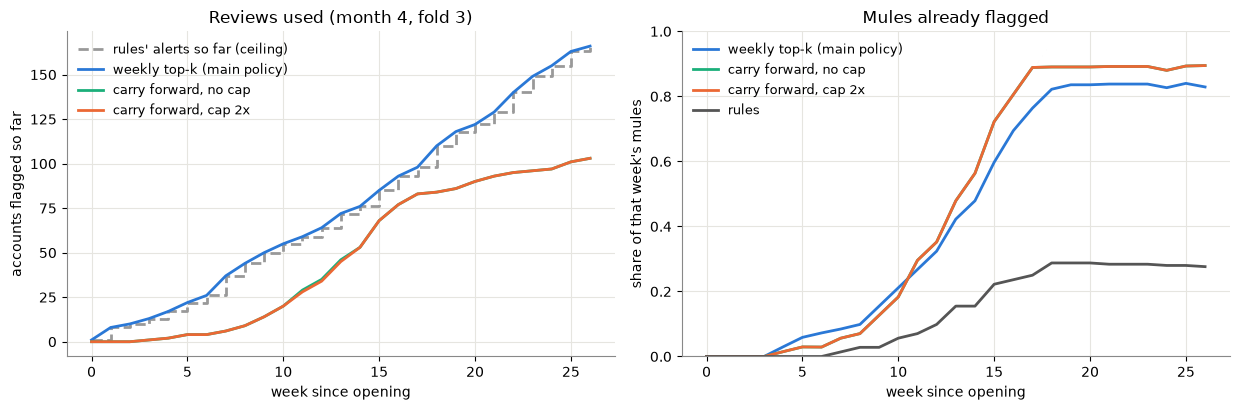

In [10]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.edgecolor": "#888", "font.size": 10})
COLORS = {"topk": "#2a78d6", "carry_nocap": "#1baf7a", "carry_cap": "#eb6834", "rules": "#555555"}
LABELS = {"topk": "weekly top-k (main policy)", "carry_nocap": "carry forward, no cap",
          "carry_cap": "carry forward, cap 2x", "rules": "rules"}
figs = []
w3 = WEEKLY_FLAGS[(WEEKLY_FLAGS.seed == 42) & (WEEKLY_FLAGS.fold == 3)].sort_values("week")
names = {"topk": "topk", "rules": "rules"}
for cap in ("nocap", "cap"):
    names[f"carry_{cap}"] = f"carry_{cap}_q{CH42[cap]}"
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].step(w3["week"], w3["budget"].cumsum(), where="post", color="#999", lw=2, ls="--",
             label="rules' alerts so far (ceiling)")
for key in ("topk", "carry_nocap", "carry_cap"):
    axes[0].plot(w3["week"], w3[f"flagged_{names[key]}"], color=COLORS[key], lw=2, label=LABELS[key])
for key in ("topk", "carry_nocap", "carry_cap", "rules"):
    axes[1].plot(w3["week"], w3[f"catch_{names[key]}"], color=COLORS[key], lw=2, label=LABELS[key])
axes[0].set(xlabel="week since opening", ylabel="accounts flagged so far", title="Reviews used (month 4, fold 3)")
axes[1].set(xlabel="week since opening", ylabel="share of that week's mules", ylim=(0, 1),
            title="Mules already flagged")
axes[0].legend(frameon=False, fontsize=9)
axes[1].legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(REPORT / "01_budget_spend.png", dpi=130)
figs.append("01_budget_spend.png")
plt.show() if "ipykernel" in sys.modules else plt.close(fig)

## 4. Investigation 2a: the application score by opening month (no labels of months 5–7)

The application model is fitted **exactly as `models.train` fits it** for the frozen model (all accounts of months
0–4, label "mule by the end of week 26", logistic regression with balanced class weights on the 56 cleaned columns),
then scores **every** account of months 0–7 from its public cleaned application columns. The same is repeated
**without the three `velocity_*` columns** (53 columns).

**Pre-registered reading.** Rank months 6 and 7 together, as the test cohort will be. For each month, compare its
share of the top 1% (and top 0.1%) of application scores with its share of the accounts. The **tilt** is month 7's gap
between the two shares; it counts as a clear tilt if larger than 2 binomial standard errors. Dropping the columns
"shrinks the tilt clearly" if month 7's top-1% gap is at most half of what it was AND its top-0.1% gap does not grow.
A tilt can also be real (a month with more fake accounts should get more top scores), which is why part (b) checks
the cost on labelled months.

In [11]:
APPM = {"with velocity": drift.app_model(DATA), "without velocity": drift.app_model(DATA, drop=drift.VELOCITY)}
coef = pd.Series(APPM["with velocity"]["coef"], index=APPM["with velocity"]["columns"])
print("velocity coefficients in the frozen recipe (log-odds per SD):", coef[drift.VELOCITY].round(3).to_dict())
print("largest |coefficient|s:", coef.abs().sort_values(ascending=False).head(6).round(3).to_dict())

S = {v: drift.score_months(DATA, m) for v, m in APPM.items()}
BY_MONTH = pd.concat([drift.month_summary(s).assign(variant=v) for v, s in S.items()], ignore_index=True)
TILT = pd.concat([drift.month_tilt(s, months).assign(variant=v, ranked_together="+".join(map(str, months)))
                  for v, s in S.items() for months in ((6, 7), (3, 4))], ignore_index=True)
rho = S["with velocity"]["app_score"].corr(S["without velocity"]["app_score"], method="spearman")
show(BY_MONTH.pivot(index="open_month", columns="variant", values=["mean", "p99", "p99.9"]).round(3))
show(TILT.round(3))
print(f"rank correlation of the two scores over all accounts: {rho:.3f}")

velocity coefficients in the frozen recipe (log-odds per SD): {'velocity_6h': -0.018, 'velocity_24h': 0.128, 'velocity_4w': 0.166}
largest |coefficient|s: {'current_address_months_count_missing': 4.599, 'housing_status_BF': 2.889, 'session_length_in_minutes_missing': 2.232, 'housing_status_BA': 1.286, 'device_os_linux': 0.922, 'intended_balcon_amount_missing': 0.899}


mean                            p99                   \
variant    with velocity without velocity with velocity without velocity   
open_month                                                                 
0                 -0.786           -0.983         2.282            2.003   
1                 -0.819           -0.836         2.229            2.141   
2                 -0.915           -0.907         2.138            2.082   
3                 -0.906           -0.792         2.318            2.367   
4                 -0.836           -0.635         2.318            2.433   
5                 -1.102           -0.787         1.886            2.139   
6                 -1.137           -0.748         1.915            2.233   
7                 -1.465           -0.871         1.621            2.167   

                   p99.9                   
variant    with velocity without velocity  
open_month                                 
0                  3.399            3.054  
1                  3.222            3.179  
2                  3.156            3.094  
3                  3.294            3.350  
4                  3.100            3.200  
5                  2.833            3.072  
6                  2.886            3.159  
7                  2.510            2.971

,open_month,accounts,share_accounts,top_0.001_k,top_0.001_n,top_0.001_share,top_0.001_ratio,top_0.01_k,top_0.01_n,top_0.01_share,top_0.01_ratio,variant,ranked_together
0,6,26529,0.53,50,37,0.740,1.396,501,330,0.659,1.243,with velocity,6+7
1,7,23532,0.47,50,13,0.260,0.553,501,171,0.341,0.726,with velocity,6+7
2,3,36724,0.54,68,44,0.647,1.198,680,368,0.541,1.002,with velocity,3+4
3,4,31279,0.46,68,24,0.353,0.767,680,312,0.459,0.998,with velocity,3+4
4,6,26529,0.53,50,33,0.660,1.245,501,282,0.563,1.062,without velocity,6+7
5,7,23532,0.47,50,17,0.340,0.723,501,219,0.437,0.930,without velocity,6+7
6,3,36724,0.54,68,44,0.647,1.198,680,343,0.504,0.934,without velocity,3+4
7,4,31279,0.46,68,24,0.353,0.767,680,337,0.496,1.077,without velocity,3+4


rank correlation of the two scores over all accounts: 0.968


In [12]:
def tilt_gap(variant, top):
    r = TILT[(TILT.variant == variant) & (TILT.ranked_together == "6+7") & (TILT.open_month == 7)].iloc[0]
    p, k = r["share_accounts"], r[f"top_{top:g}_k"]
    return r[f"top_{top:g}_share"] - p, np.sqrt(p * (1 - p) / k)

G = {(v, top): tilt_gap(v, top) for v in APPM for top in (0.01, 0.001)}
for (v, top), (g, se) in G.items():
    print(f"{v:17s} top {top:.1%}: month 7 share of top minus share of accounts {g:+.3f} (2 SE = {2 * se:.3f})")
clear_tilt = abs(G[("with velocity", 0.01)][0]) > 2 * G[("with velocity", 0.01)][1]
shrinks = (abs(G[("without velocity", 0.01)][0]) <= 0.5 * abs(G[("with velocity", 0.01)][0])
           and abs(G[("without velocity", 0.001)][0]) <= abs(G[("with velocity", 0.001)][0]))
COND_I = bool(clear_tilt and shrinks)
print(f"clear tilt with velocity: {clear_tilt}; shrinks clearly without: {shrinks} -> condition (i) {COND_I}")

with velocity     top 1.0%: month 7 share of top minus share of accounts -0.129 (2 SE = 0.045)
with velocity     top 0.1%: month 7 share of top minus share of accounts -0.210 (2 SE = 0.141)
without velocity  top 1.0%: month 7 share of top minus share of accounts -0.033 (2 SE = 0.045)
without velocity  top 0.1%: month 7 share of top minus share of accounts -0.130 (2 SE = 0.141)
clear tilt with velocity: True; shrinks clearly without: True -> condition (i) True


Which cleaned application columns move most with the calendar? Mean of months 6 and 7 minus mean of months 0–4, in
units of the months 0–4 standard deviation (no labels).

In [13]:
lin = pd.read_parquet(Path(DATA) / "features" / "accounts_linear.parquet")
cols = [c for c in lin.columns if c not in ("account_id", "open_month")]
tr_, te_ = lin[lin.open_month.isin(MONTHS)], lin[lin.open_month.isin([6, 7])]
COL_DRIFT = (((te_[cols].mean() - tr_[cols].mean()) / tr_[cols].std().replace(0, np.nan))
             .rename("shift_sd").to_frame().assign(coef=coef.reindex(cols))
             .sort_values("shift_sd", key=abs, ascending=False))
show(COL_DRIFT.head(10).round(3))
del lin, tr_, te_

,shift_sd,coef
velocity_4w,-2.218,0.166
velocity_24h,-1.318,0.128
velocity_6h,-0.858,-0.018
zip_count_4w,-0.697,-0.013
date_of_birth_distinct_emails_4w,-0.497,-0.201
credit_risk_score,0.288,0.015
income,0.279,0.157
session_length_in_minutes,-0.208,0.021
phone_home_valid,0.153,-0.637
email_is_free,-0.136,0.315


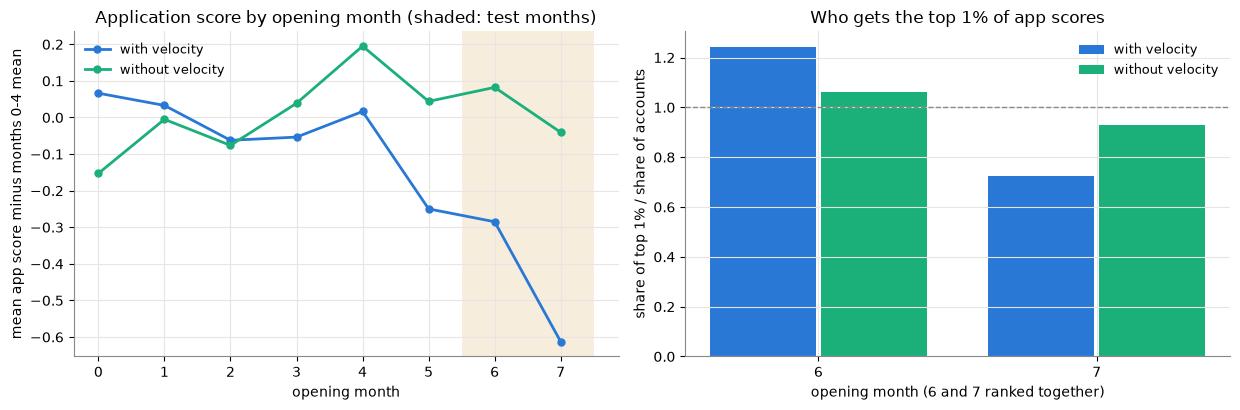

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
VC = {"with velocity": "#2a78d6", "without velocity": "#1baf7a"}
for v in APPM:
    b = BY_MONTH[BY_MONTH.variant == v]
    axes[0].plot(b["open_month"], b["mean"] - b.loc[b.open_month.isin(MONTHS), "mean"].mean(), color=VC[v], lw=2,
                 marker="o", ms=5, label=v)
    t = TILT[(TILT.variant == v) & (TILT.ranked_together == "6+7")].set_index("open_month")
    axes[1].bar([6 + (0.2 if v == "without velocity" else -0.2), 7 + (0.2 if v == "without velocity" else -0.2)],
                t["top_0.01_ratio"], width=0.38, color=VC[v], label=v)
axes[0].axvspan(5.5, 7.5, color="#f3e2c7", alpha=0.6, lw=0)
axes[0].set(xlabel="opening month", ylabel="mean app score minus months 0-4 mean",
            title="Application score by opening month (shaded: test months)")
axes[1].axhline(1, color="#888", ls="--", lw=1)
axes[1].set(xticks=[6, 7], xlabel="opening month (6 and 7 ranked together)",
            ylabel="share of top 1% / share of accounts", title="Who gets the top 1% of app scores")
axes[0].legend(frameon=False, fontsize=9)
axes[1].legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(REPORT / "02_app_score_by_month.png", dpi=130)
figs.append("02_app_score_by_month.png")
plt.show() if "ipykernel" in sys.modules else plt.close(fig)

## 5. Investigation 2b: a mixed cohort on the folds

To imitate the test cohort (two opening months ranked together), the tuned model is trained on months 0–2 and scores
**months 3 and 4 ranked together** as one cohort; its weekly budget is the rules' alerts on months 3 and 4 combined in
each week of life. Two application scores: the normal one, and one **without `velocity_*`** (same recipe, 53 columns).
The same scores are also read month by month (validate 3, validate 4), and month 4 is also scored by the lab's fold 3
model (trained on months 0–3), for both variants. Seed 42 only. The normal variant reuses the seed-42 fits of §2.

Measures: harness-style **caught** at the rules' budget (permanent flags), median days from start, precision;
`catch_rules` and `catch_0.1pct` (the lab's catch curves, mean over weeks 0–26); `weekly_recall` (share of each week's
mules in that week's top 1%). And for the mixed cohort: the **share of flags going to month 3 vs month 4** against each
month's share of the mules.

**Pre-registered verdict.** Recommend dropping `velocity_*` from the application score only if (i) the month tilt of
§4 shrinks clearly AND (ii) here no measure gets worse by more than its noise: `catch_rules` 0.010, `catch_0.1pct`
0.008, `weekly_recall` 0.008 (seed SDs of PR #43), caught = the largest seed SD of the main policy's catches in §3,
at least 1 account.
Median days and precision are shown without a verdict (no noise level was set for them). Either way, it changes the
frozen application-score recipe, so it is a **team decision**.

In [15]:
t = time.time()
APP_NV = {"0-2": drift.fold_app_scores(DATA, (0, 1, 2), (3, 4), drop=drift.VELOCITY),
          "0-3": drift.fold_app_scores(DATA, (0, 1, 2, 3), (4,), drop=drift.VELOCITY)}
B = {("with velocity", "0-2"): OOF[(42, 2)], ("with velocity", "0-3"): OOF[(42, 3)],
     ("without velocity", "0-2"): drift.fit_score(df, (0, 1, 2), (3, 4), APP_NV["0-2"], PARAMS, 42),
     ("without velocity", "0-3"): drift.fit_score(df, (0, 1, 2, 3), (4,), APP_NV["0-3"], PARAMS, 42)}
print(f"2 fits without velocity ({time.time() - t:.0f}s)")
TRUTH34 = pd.concat([TRUTH[3], TRUTH[4]], ignore_index=True)
MONTH_OF = TRUTH34.set_index("account_id")["open_month"]


def cohort_measures(o, months):
    live = o[o.open_month.isin(months)]
    k = {w: sum(K[m].get(w, 0) for m in months) for w in range(WEEKS[0], WEEKS[1] + 1)}
    truth = TRUTH34[TRUTH34.open_month.isin(months)]
    mule_wk = CTX["mules"][CTX["mules"].open_month.isin(months)]
    first_h = sc.permanent_flags(live, k)                 # harness tie rule (account id)
    first_r = fl.first_flag_weeks(live, k)               # the lab's catch_rules
    first_p = fl.first_flag_weeks(live, fl.pct_budget(live))
    summ = sc.measures(truth, {"model": first_h}, W_HI)[0].iloc[0]
    v = fl.weekly_top1(live, live["score"].to_numpy())
    mules = truth["account_id"][sc.mule_at(truth, W_HI)]
    m = {"budget": sum(k.values()), "flagged": int(summ.flagged), "caught": int(summ.caught), "mules": int(summ.mules),
         "precision": summ.precision, "median_days_from_start": summ.median_days_from_start,
         "catch_rules": fl.catch_mean(first_r, mule_wk), "catch_0.1pct": fl.catch_mean(first_p, mule_wk),
         "weekly_recall": fl.weekly_recall(v)}
    shares = pd.concat([drift.flag_shares(first_h, MONTH_OF, mules).assign(flags_from="rules budget"),
                        drift.flag_shares(first_p, MONTH_OF, mules).assign(flags_from="0.1% a week")])
    return m, shares


COHORTS = [("months 3+4 together", "0-2", (3, 4)), ("month 3", "0-2", (3,)), ("month 4", "0-2", (4,)),
           ("month 4, lab fold 3", "0-3", (4,))]
rows, share_rows = [], []
for variant in ("with velocity", "without velocity"):
    for name, tm, months in COHORTS:
        m, shares = cohort_measures(B[(variant, tm)], months)
        rows.append({"variant": variant, "cohort": name, "train_months": tm, **m})
        if len(months) > 1:
            share_rows.append(shares.assign(variant=variant))
MIXED = pd.DataFrame(rows)
SHARES = pd.concat(share_rows, ignore_index=True)

# the single-month catch measures must equal the lab's own (feature_lab.catch_measures)
for (variant, tm, m_) in (("with velocity", "0-2", 3), ("with velocity", "0-3", 4)):
    o = B[(variant, tm)][lambda d: d.open_month == m_]
    c = fl.catch_measures(fl.weekly_top1(o, o["score"].to_numpy()), m_, CTX)
    r = MIXED[(MIXED.variant == variant) & (MIXED.train_months == tm) & (MIXED.cohort.str.startswith(f"month {m_}"))]
    assert abs(c["catch_rules"] - r["catch_rules"].iat[0]) < 1e-12 and abs(c["catch_0.1pct"] - r["catch_0.1pct"].iat[0]) < 1e-12
show(MIXED.round(3))
show(SHARES.round(3))

2 fits without velocity (157s)


,variant,cohort,train_months,budget,flagged,caught,mules,precision,median_days_from_start,catch_rules,catch_0.1pct,weekly_recall
0,with velocity,months 3+4 together,0-2,331,331,124,146,0.375,7.0,0.452,0.535,0.408
1,with velocity,month 3,0-2,165,165,59,70,0.358,8.0,0.453,0.533,0.397
2,with velocity,month 4,0-2,166,166,63,76,0.380,6.0,0.430,0.532,0.415
3,with velocity,"month 4, lab fold 3",0-3,166,166,63,76,0.380,7.0,0.436,0.562,0.465
4,without velocity,months 3+4 together,0-2,331,331,125,146,0.378,7.0,0.452,0.540,0.415
5,without velocity,month 3,0-2,165,165,59,70,0.358,8.0,0.456,0.538,0.409
6,without velocity,month 4,0-2,166,166,63,76,0.380,7.0,0.418,0.541,0.421
7,without velocity,"month 4, lab fold 3",0-3,166,166,64,76,0.386,8.0,0.436,0.551,0.452


,open_month,flags,share_flags,mules,share_mules,flags_from,variant
0,3,157,0.474,70,0.479,rules budget,with velocity
1,4,174,0.526,76,0.521,rules budget,with velocity
2,3,920,0.501,70,0.479,0.1% a week,with velocity
3,4,916,0.499,76,0.521,0.1% a week,with velocity
4,3,155,0.468,70,0.479,rules budget,without velocity
5,4,176,0.532,76,0.521,rules budget,without velocity
6,3,902,0.491,70,0.479,0.1% a week,without velocity
7,4,934,0.509,76,0.521,0.1% a week,without velocity


In [16]:
NOISE_B = {**NOISE, "caught": max(1.0, float(SEED_SD["caught"].max()))}   # at least one account
cols_d = list(NOISE_B) + ["median_days_from_start", "precision"]
a_ = MIXED[MIXED.variant == "without velocity"].set_index("cohort")[cols_d]
b_ = MIXED[MIXED.variant == "with velocity"].set_index("cohort")[cols_d]
DELTA = (a_ - b_.reindex(a_.index)).reset_index()
worse = {m: bool((DELTA[m] < -n).any()) for m, n in NOISE_B.items()}
COND_II = not any(worse.values())
show(DELTA.round(3))
print("noise levels:", {m: round(n, 3) for m, n in NOISE_B.items()})
print("worse by more than noise somewhere:", worse, "-> condition (ii)", COND_II)
RECOMMEND_DROP = COND_I and COND_II
print(f"(i) {COND_I}, (ii) {COND_II} -> recommend dropping velocity_* from the app score: {RECOMMEND_DROP} "
      "(a team decision either way)")

,cohort,catch_rules,catch_0.1pct,weekly_recall,caught,median_days_from_start,precision
0,months 3+4 together,0.001,0.005,0.007,1,0.0,0.003
1,month 3,0.003,0.005,0.012,0,0.0,0.000
2,month 4,-0.012,0.008,0.006,0,1.0,0.000
3,"month 4, lab fold 3",0.000,-0.012,-0.013,1,1.0,0.006


noise levels: {'catch_rules': 0.01, 'catch_0.1pct': 0.008, 'weekly_recall': 0.008, 'caught': 1.155}
worse by more than noise somewhere: {'catch_rules': True, 'catch_0.1pct': True, 'weekly_recall': True, 'caught': False} -> condition (ii) False
(i) True, (ii) False -> recommend dropping velocity_* from the app score: False (a team decision either way)


## 6. Number of looks, and the report

Every comparison judged on the same folds raises the chance that something wins by luck. New looks at the v1_full
folds of months 0–4 in this notebook: **10 policy candidates** (5 quantiles × cap / no cap) on folds 1–2, of which
**2** (the chosen quantile with and without cap) were scored on fold 3, the same per seed; and **1 application-score
variant** (without `velocity_*`) on months 3, 4 and the mixed cohort. That is **11 new candidates** in all, and 11
LightGBM fits.

In [17]:
LOOKS = {"policy_candidates_on_folds_1_2": 2 * len(pol.QUANTILES), "policy_candidates_on_fold_3": 2,
         "app_score_variants": 1, "new_candidates_total": 2 * len(pol.QUANTILES) + 1,
         "lightgbm_fits": len(OOF) + 2, "seeds": list(SEEDS)}
POL.to_csv(REPORT / "policy_folds.csv", index=False)
CHOICE.to_csv(REPORT / "policy_choice.csv", index=False)
GAIN.to_csv(REPORT / "policy_gain.csv", index=False)
BY_MONTH.to_csv(REPORT / "app_score_by_month.csv", index=False)
TILT.to_csv(REPORT / "app_score_tilt.csv", index=False)
COL_DRIFT.rename_axis("column").to_csv(REPORT / "column_drift.csv")
MIXED.to_csv(REPORT / "mixed_cohort.csv", index=False)
SHARES.to_csv(REPORT / "mixed_cohort_flag_shares.csv", index=False)
DELTA.to_csv(REPORT / "mixed_cohort_delta.csv", index=False)


def fmt(x):
    return x.to_markdown(floatfmt=".3f")


c42 = CHOICE[CHOICE.seed == 42].set_index("cap")
verdicts = CHOICE.pivot(index="seed", columns="cap", values="verdict").reindex(list(SEEDS))
g42 = GAIN[GAIN.seed == 42]
tk42 = POL[(POL.seed == 42) & (POL.policy == "topk")].set_index("fold")
any42 = POL[(POL.seed == 42) & (POL.policy == "model_anytime")].set_index("fold")
r42 = POL[(POL.seed == 42) & (POL.policy == "rules")].set_index("fold")
gw, gwo = G[("with velocity", 0.01)], G[("without velocity", 0.01)]
mix = MIXED[MIXED.cohort == "months 3+4 together"].set_index("variant")
sh = SHARES[(SHARES.flags_from == "rules budget")].set_index(["variant", "open_month"])
summary = [
    f"# Carry-forward budget policy and calendar drift in the application score", "",
    f"Data `{DATA}` (this Mac's copy, run_manifest sha256 {RUN_HASH[:6]}..., which differs from the training "
    "machine's): numbers are for comparison only. Months 0-4 only; month 5 and months 6-7 untouched (months 5-7 read "
    f"only as public cleaned application columns in 2a). Tuned model `frozen_tuned` settings, 38 frozen inputs. "
    f"Executed {time.strftime('%Y-%m-%d %H:%M')} in {(time.time() - T0) / 60:.0f} min. Notebook "
    "`notebooks/11_policy_drift.ipynb`.", "",
    "## Summary", "",
    f"**1. Carry unused budget forward (secondary policy).** Pre-registered choice on folds 1+2, applied to fold 3. "
    f"Seed 42: no cap chose quantile {c42.loc['nocap', 'quantile']}, verdict **{c42.loc['nocap', 'verdict']}**; "
    f"cap 2x chose {c42.loc['cap', 'quantile']}, verdict **{c42.loc['cap', 'verdict']}**. "
    f"Caught per fold (1 / 2 / 3), main weekly top-k {' / '.join(str(int(tk42.loc[f, 'caught'])) for f in (1, 2, 3))}; "
    f"carry no cap {' / '.join(str(int(c42.loc['nocap', f'caught_f{f}'])) for f in (1, 2, 3))}; "
    f"carry cap {' / '.join(str(int(c42.loc['cap', f'caught_f{f}'])) for f in (1, 2, 3))}; "
    f"model_anytime (upper bound) {' / '.join(str(int(any42.loc[f, 'caught'])) for f in (1, 2, 3))}; "
    f"rules {' / '.join(str(int(r42.loc[f, 'caught'])) for f in (1, 2, 3))}. "
    f"Seed SD of the main policy's catches: up to {SEED_SD['caught'].max():.1f} per fold. "
    f"Verdicts over seeds 42 / 1 / 2: no cap {' / '.join(verdicts['nocap'])}; cap {' / '.join(verdicts['cap'])}. "
    "This is a secondary result beside the agreed main policy, never a replacement; at every week the model used "
    "no more reviews than the rules (checked).", "",
    f"**2. Calendar drift in the application score.** (a) Months 6+7 ranked together: month 7's share of the top 1% "
    f"minus its share of accounts is {gw[0]:+.3f} with velocity_* (2 SE {2 * gw[1]:.3f}) and {gwo[0]:+.3f} without. "
    f"Condition (i) (clear tilt that shrinks by half or more): **{COND_I}**. (b) Months 3+4 ranked together, train "
    f"0-2: caught {int(mix.loc['with velocity', 'caught'])} vs {int(mix.loc['without velocity', 'caught'])} of "
    f"{int(mix.loc['with velocity', 'mules'])}, catch_rules {mix.loc['with velocity', 'catch_rules']:.3f} vs "
    f"{mix.loc['without velocity', 'catch_rules']:.3f}, catch_0.1pct {mix.loc['with velocity', 'catch_0.1pct']:.3f} vs "
    f"{mix.loc['without velocity', 'catch_0.1pct']:.3f}, weekly recall {mix.loc['with velocity', 'weekly_recall']:.3f} "
    f"vs {mix.loc['without velocity', 'weekly_recall']:.3f} (with vs without velocity_*). Condition (ii) (no measure "
    f"worse than noise on any of the 4 cohorts): **{COND_II}**. Recommendation to drop velocity_*: "
    f"**{'yes' if RECOMMEND_DROP else 'no'}**; it would change the frozen app-score recipe, so a team decision "
    "either way.", "",
    f"Looks: {LOOKS['new_candidates_total']} new candidates on the {RUN} folds (10 policy candidates on folds 1-2, "
    f"2 of them on fold 3, per seed; 1 app-score variant), {LOOKS['lightgbm_fits']} LightGBM fits.", ""]
body = [
    "## Investigation 1: carry unused budget forward", "",
    "### Pre-registered choice and verdict per seed", "", CHOICE.to_markdown(index=False, floatfmt=".4g"), "",
    "### Seed 42: all policies per fold (fold 3 = held back)", "", fmt(T42), "",
    "### Gain over the main policy (chosen quantile)", "", GAIN.to_markdown(index=False, floatfmt=".3f"), "",
    "### Seed noise of the main policy (3 seeds)", "", fmt(SEED_SD), "",
    "![budget spend](01_budget_spend.png)", "",
    "- topk: the agreed main policy (score.permanent_flags). carry: evaluation.policy.carry_forward_flags with the "
    "quantile chosen on folds 1+2. model_anytime: score.anytime_flags, same total flags spent at any time (not fair "
    "week by week; upper bound). rules: the rules' first alerts.",
    "- tau is a quantile of the whole month's 27 weeks of scores, known only at the end of the horizon; in use it "
    "would be fixed in score units beforehand (e.g. on month 5). No label is involved, but the result is optimistic "
    "in that respect.", "",
    "## Investigation 2: calendar drift in the application score", "",
    "### (a) App score per opening month (label-free for months 5-7)", "",
    BY_MONTH.pivot(index="open_month", columns="variant", values=["mean", "p99", "p99.9"]).to_markdown(floatfmt=".3f"),
    "", "### (a) Share of the top 0.1% / 1% when months are ranked together", "",
    TILT.to_markdown(index=False, floatfmt=".3f"), "",
    f"Velocity coefficients in the frozen recipe: {coef[drift.VELOCITY].round(3).to_dict()}. Rank correlation of the "
    f"two scores over all accounts: {rho:.3f}.", "",
    "### Columns that move most with the calendar (months 6+7 vs 0-4, in SD of months 0-4)", "",
    fmt(COL_DRIFT.head(10)), "", "![app score by month](02_app_score_by_month.png)", "",
    "### (b) Mixed cohort on the folds (seed 42)", "", MIXED.to_markdown(index=False, floatfmt=".3f"), "",
    "Without minus with velocity_*:", "", DELTA.to_markdown(index=False, floatfmt=".3f"), "",
    f"Noise levels: {json.dumps({m: round(n, 3) for m, n in NOISE_B.items()})}.", "",
    "### (b) Where the mixed cohort's flags go", "", SHARES.to_markdown(index=False, floatfmt=".3f"), ""]
(REPORT / "report.md").write_text("\n".join(summary + body) + "\n")
(REPORT / "settings.json").write_text(json.dumps(
    {"data": DATA, "run_manifest_sha256": RUN_HASH, "params": PARAMS, "seeds": list(SEEDS),
     "quantiles": list(pol.QUANTILES), "cap": pol.CAP, "noise": NOISE_B, "looks": LOOKS,
     "minutes": round((time.time() - T0) / 60, 1), "lightgbm": lgb.__version__}, indent=2))
print("\n".join(summary))
print(f"-> {REPORT}")

# Carry-forward budget policy and calendar drift in the application score

Data `/Users/cheepheng/aml-detection-system/data/v1_full` (this Mac's copy, run_manifest sha256 4ce1c4..., which differs from the training machine's): numbers are for comparison only. Months 0-4 only; month 5 and months 6-7 untouched (months 5-7 read only as public cleaned application columns in 2a). Tuned model `frozen_tuned` settings, 38 frozen inputs. Executed 2026-10-29 05:20 in 11 min. Notebook `notebooks/11_policy_drift.ipynb`.

## Summary

**1. Carry unused budget forward (secondary policy).** Pre-registered choice on folds 1+2, applied to fold 3. Seed 42: no cap chose quantile 0.9995, verdict **better**; cap 2x chose 0.9995, verdict **better**. Caught per fold (1 / 2 / 3), main weekly top-k 57 / 59 / 63; carry no cap 58 / 61 / 68; carry cap 58 / 61 / 68; model_anytime (upper bound) 58 / 61 / 69; rules 19 / 18 / 21. Seed SD of the main policy's catches: up to 1.2 per fold. Verdicts over seeds 42 / 1 / 2: 

## Interpretation (written after the run, 29 Oct 2026)

Numbers come from this Mac's copy of `data/v1_full` (run_manifest sha256 4ce1c4..., not the training machine's copy),
so use them to compare policies and variants with each other, not as final results.

**Investigation 1: carry unused budget forward.**
- The pre-registered choice was the strictest threshold in the grid (quantile 0.9995) for all 3 seeds, with and
  without the cap. The best threshold might be stricter still. The grid was not widened, to keep the pre-registration.
- On the held-back fold 3, carrying budget forward caught **68 vs 63** mules (seed 42), 66 / 65 vs 64 (seed 1) and
  67 / 65 vs 64 (seed 2), no cap / cap. The median first flag came 1–2 days sooner (6 vs 7–8 days after the laundering
  start). Verdict: **"holds up" with all 3 seeds**. It was "better" only with seed 42: on fold 1 the gain is 0 or −1
  with seeds 1 and 2.
- Seed noise: the main policy's catches move by an SD of 0.6–1.2 accounts between seeds. Seed 42's +5 on fold 3 is
  clearly more than that. Seeds 1 and 2 gain +1 to +3, which is at the edge of the noise.
- The clearest gain is in **reviews used**. On fold 3 the policy flagged only 103 accounts where the rules raised 166
  alerts, and still caught more: precision 0.66 vs 0.38. On folds 1–2 it used 134–149 of 165–170. It nearly matches
  `model_anytime` (69 on fold 3), the upper bound that ignores the weekly fairness limit.
- The 2× weekly cap hardly matters: on fold 3 with seed 42 the cap and no-cap flags are identical (the two lines in the
  first figure overlap).
- Caveats. The threshold is set as a share of the whole month's 27 weeks of scores, so it uses the shape of future
  scores (no labels). In use it would need a threshold fixed in score units beforehand, e.g. on month 5 with the
  calibration step. Each fold has only 64–76 mules. This is a **secondary** policy beside the agreed weekly top-k,
  never a replacement.

**Investigation 2: calendar drift in the application score.**
- (a) Ranked together with month 6, **month-7 accounts get too few of the top application scores**: they are 47% of
  the test cohort's accounts but get 34% of its top 1% and 26% of its top 0.1%. The cause is the velocity columns. Their
  coefficients are positive (+0.13 for `velocity_24h`, +0.17 for `velocity_4w`), and velocity falls with the calendar
  month, so later months look safer. Without them month 7 gets 44% of the top 1% and 34% of the top 0.1%. The top-1%
  gap shrinks from −12.9 to −3.3 points (2 SE = 4.5), so condition (i) is met. Part of a tilt could be real (if month 7
  had fewer fake accounts), but that cannot be checked without labels of months 6–7.
- (b) On months 3 + 4 ranked together, dropping velocity changes almost nothing: 124 vs 125 caught of 146,
  `catch_rules` 0.452 both, `catch_0.1pct` +0.005, weekly recall +0.007. The single-month checks are mixed. Three
  measures fall by slightly more than their noise level: month 4 `catch_rules` −0.012 (noise 0.010), and on the lab's
  fold 3 `catch_0.1pct` −0.012 and weekly recall −0.013 (noise 0.008). The others rise. So condition (ii) is not met,
  but only narrowly. These are single-seed differences between two models, and the noise of a difference is about
  1.4 times the noise of one model.
- **Pre-registered recommendation: do not drop `velocity_*` (no).** Changing the frozen application-score recipe is a
  team decision either way.
- Limitation of (b). Months 3 and 4 differ much less in velocity than months 6 and 7 (`velocity_4w` −0.54 vs −0.94,
  against −1.69 vs −2.81), and the current application score shows no tilt between them (top-1% ratio 1.00). So (b)
  can show the cost of dropping the columns but not the benefit. At the rules' budget the flags split between months
  3 and 4 like the mules do, in both variants.

**Side finding.** The feature lab and notebook 08 pass `app_score` to LightGBM as float64, while `models.train` (the
frozen model) and this notebook cast it to float32. That changes LightGBM's bins: on fold 2 the weekly recall is
0.3991 vs 0.3966, which is inside seed noise.